In [9]:
import warnings

warnings.filterwarnings("ignore", category=DeprecationWarning)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [10]:
!pip install mlxtend

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

In [12]:

df = pd.read_csv('/content/Groceries_dataset .csv')
df

,Member_number,Date,itemDescription
0,1808,21-07-2015,tropical fruit
1,2552,05-01-2015,whole milk
2,2300,19-09-2015,pip fruit
3,1187,12-12-2015,other vegetables
4,3037,01-02-2015,whole milk
...,...,...,...
38760,4471,08-10-2014,sliced cheese
38761,2022,23-02-2014,candy
38762,1097,16-04-2014,cake bar
38763,1510,03-12-2014,fruit/vegetable juice


In [13]:
df.head()

,Member_number,Date,itemDescription
0,1808,21-07-2015,tropical fruit
1,2552,05-01-2015,whole milk
2,2300,19-09-2015,pip fruit
3,1187,12-12-2015,other vegetables
4,3037,01-02-2015,whole milk


In [14]:
# Display dataset shape
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns)

# Display unique grocery items
print("\nUnique Items:",
      df['itemDescription'].nunique())

# Display unique customers
print("\nUnique Customers:",
      df['Member_number'].nunique())


Dataset Shape: (38765, 3)

Column Names:
Index(['Member_number', 'Date', 'itemDescription'], dtype='object')

Unique Items: 167

Unique Customers: 3898


In [15]:

# Create basket using Member_number and Date

df['basket'] = (
    df['Member_number'].astype(str) + '_' +
    df['Date'].astype(str)
)

# Group items into transactions

transactions = df.groupby(
    'basket'
)['itemDescription'].apply(list).tolist()

# Display first two transactions

print("First Two Transactions:")
print(transactions[:2])

# Total number of baskets

print("\nTotal Transactions:", len(transactions))


First Two Transactions:
[['sausage', 'whole milk', 'semi-finished bread', 'yogurt'], ['whole milk', 'pastry', 'salty snack']]

Total Transactions: 14963


In [16]:
# Create TransactionEncoder

te = TransactionEncoder()

# Transform transactions

te_array = te.fit_transform(transactions)

# Convert into DataFrame

basket_table = pd.DataFrame(
    te_array,
    columns=te.columns_
)

# Display encoded data

basket_table.head()


,Instant food products,UHT-milk,abrasive cleaner,artif. sweetener,baby cosmetics,bags,baking powder,bathroom cleaner,beef,berries,...,turkey,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,True,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [17]:
print("Encoded Basket Table Shape:",
      basket_table.shape)

Encoded Basket Table Shape: (14963, 167)


In [18]:
frequent_itemsets = apriori(
    basket_table,
    min_support=0.001,
    use_colnames=True
)

# Sort by support

frequent_itemsets = frequent_itemsets.sort_values(
    by='support',
    ascending=False
)

# Display top 10 frequent itemsets

frequent_itemsets.head(10)

,support,itemsets
146,0.157923,(whole milk)
90,0.122101,(other vegetables)
109,0.110005,(rolls/buns)
123,0.097106,(soda)
147,0.085879,(yogurt)
110,0.069572,(root vegetables)
139,0.067767,(tropical fruit)
10,0.060683,(bottled water)
115,0.060349,(sausage)
28,0.053131,(citrus fruit)


In [20]:
rules = association_rules(
    frequent_itemsets,
    metric='lift',
    min_threshold=1
)

# Sort rules by lift

rules = rules.sort_values(
    by='lift',
    ascending=False
)

# Display top 10 rules

rules[
    ['antecedents',
     'consequents',
     'support',
     'confidence',
     'lift']
].head(10)

,antecedents,consequents,support,confidence,lift
80,"(whole milk, yogurt)",(sausage),0.001470,0.131737,2.182917
85,(sausage),"(whole milk, yogurt)",0.001470,0.024363,2.182917
81,"(whole milk, sausage)",(yogurt),0.001470,0.164179,1.911760
84,(yogurt),"(whole milk, sausage)",0.001470,0.017121,1.911760
114,(specialty chocolate),(citrus fruit),0.001403,0.087866,1.653762
115,(citrus fruit),(specialty chocolate),0.001403,0.026415,1.653762
82,"(yogurt, sausage)",(whole milk),0.001470,0.255814,1.619866
83,(whole milk),"(yogurt, sausage)",0.001470,0.009310,1.619866
191,(tropical fruit),(flour),0.001069,0.015779,1.617141
190,(flour),(tropical fruit),0.001069,0.109589,1.617141


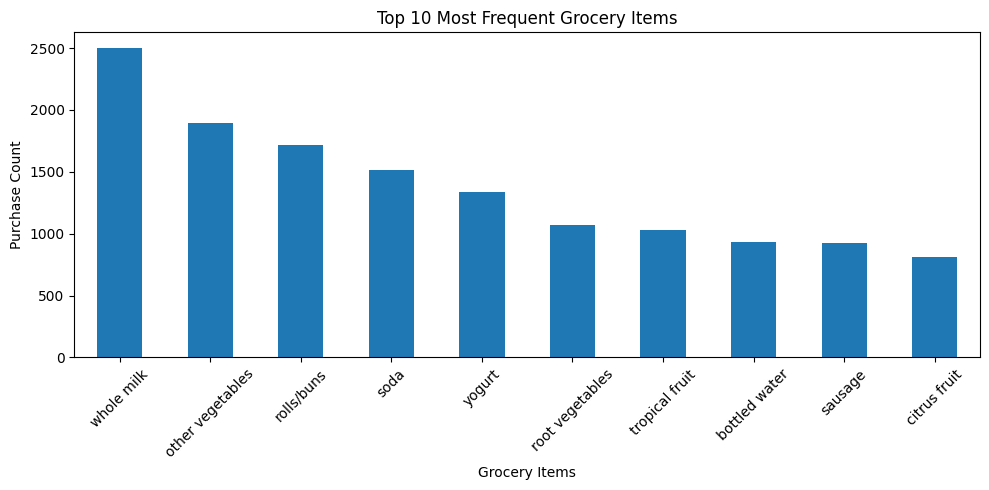

In [21]:
plt.figure(figsize=(10, 5))

df['itemDescription'].value_counts().head(10).plot(
    kind='bar'
)

plt.title('Top 10 Most Frequent Grocery Items')
plt.xlabel('Grocery Items')
plt.ylabel('Purchase Count')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


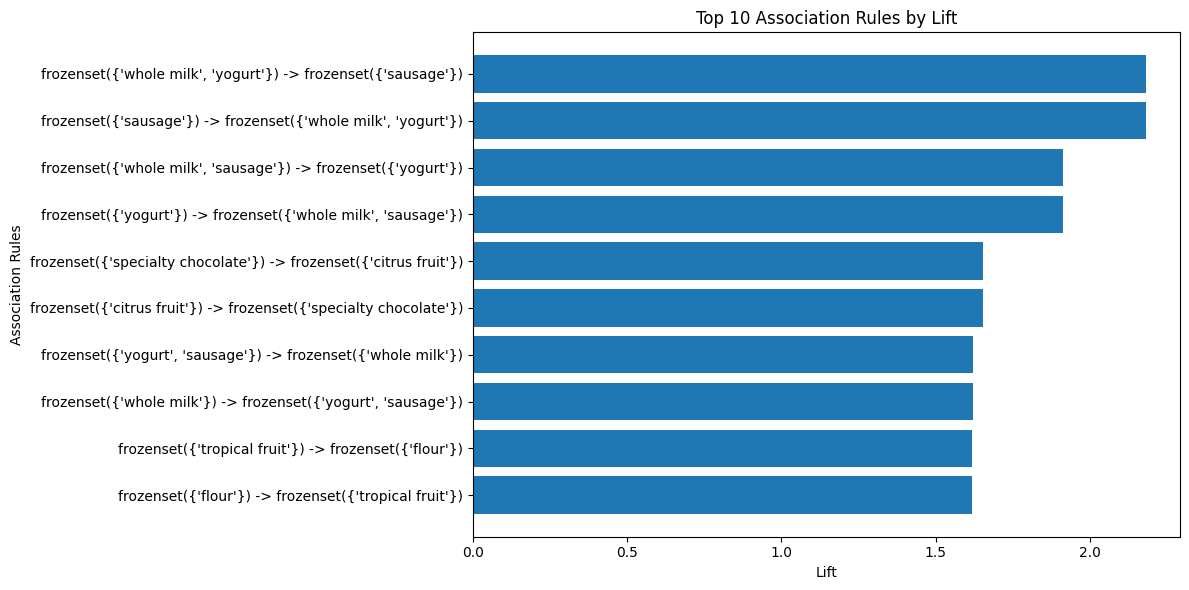

In [22]:
top_rules = rules.head(10).copy()

top_rules['Rule'] = (
    top_rules['antecedents'].astype(str)
    + ' -> ' +
    top_rules['consequents'].astype(str)
)

plt.figure(figsize=(12, 6))

plt.barh(
    top_rules['Rule'],
    top_rules['lift']
)

plt.title('Top 10 Association Rules by Lift')
plt.xlabel('Lift')
plt.ylabel('Association Rules')

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [23]:
print("========== EXPERIMENT 5 RESULTS ==========")

print("Total Transactions:", len(transactions))

print("Total Unique Items:",
      df['itemDescription'].nunique())

print("\nMost Frequently Purchased Item:")

print(df['itemDescription'].value_counts().idxmax())

print("\nHighest Lift Association Rule:")

if not rules.empty:

    best_rule = rules.iloc[0]

    print("Antecedent:", best_rule['antecedents'])

    print("Consequent:", best_rule['consequents'])

    print("Support:", best_rule['support'])

    print("Confidence:", best_rule['confidence'])

    print("Lift:", best_rule['lift'])

print("\n========== END OF EXPERIMENT ==========")

========== EXPERIMENT 5 RESULTS ==========
Total Transactions: 14963
Total Unique Items: 167

Most Frequently Purchased Item:
whole milk

Highest Lift Association Rule:
Antecedent: frozenset({'whole milk', 'yogurt'})
Consequent: frozenset({'sausage'})
Support: 0.0014702933903628951
Confidence: 0.1317365269461078
Lift: 2.1829165589087607

========== END OF EXPERIMENT ==========


In [24]:
misleading_rules = rules[
    (rules['confidence'] >= 0.5) &
    (rules['lift'] < 1.2) &
    (rules['lift'] >= 1)
]

misleading_rules = misleading_rules.sort_values(
    by='confidence',
    ascending=False
)

print("High Confidence but Lift Close to 1:")

display(
    misleading_rules[
        ['antecedents',
         'consequents',
         'support',
         'confidence',
         'lift']
    ].head(5)
)

High Confidence but Lift Close to 1:


,antecedents,consequents,support,confidence,lift
